# Bootcamp de IA Bioinspirada: “Aprendizaje desde propiedades locales”
**Universidad Austral de Chile (UACh) & Centro Nacional de Inteligencia Artificial (CENIA)**  
*Valdivia, Chile | 11, 12 y 13 de enero de 2027*

---

### Propósito del Cuaderno de Trabajo
En este bootcamp desarrollaremos, en duplas interdisciplinarias (**Ingeniería + Biología**), un prototipo de aprendizaje de máquinas que opere estrictamente basado en **propiedades locales**, donde el aprendizaje ocurre como un **fenómeno emergente**.

Con el fin de distanciarnos de las clásicas Redes Neuronales Artificiales (sin *backpropagation* ni optimización global de pesos internos), utilizaremos el **Juego de la Vida de Conway** interpretado como una **proto-red neuronal** capaz de propagar impulsos bajo restricciones locales. Cada grupo definirá **condiciones y restricciones** inspiradas en criterios neurobiológicos para lograr el mejor desempeño posible en una tarea de **navegación autónoma (evasión de obstáculos con un vehículo de Braitenberg)**.

### Estructura del Taller en este Notebook
* **Fase 0 y Configuración:** Carga del motor físico del vehículo y herramientas de visualización neurobiológica (*Raster Plot* y *Tasa de Disparo Poblacional*).
* **Día 1 (Mañana) — “La caja de arena”:** Transición desde las reglas deterministas rígidas de Conway (0 o 1) hacia reglas probabilísticas, ruido espontáneo y tipos celulares diferenciados.
* **Día 1 (Tarde) — “Sensorialidad y conducta”:** Inyección de señales sensoriales externas, decodificación motora y análisis mediante visualizaciones tradicionales de neurociencias.
* **Día 2 — “Restricciones biológicas, Clausura sensorio-motriz y Plasticidad local”:** Incorporación de metabolismo neuronal (límites de ATP/homeostasis) y reglas de plasticidad dinámica (Hebbiana espacial y no-Hebbiana) que respondan a la historia local de cada unidad. Selección evolutiva de condiciones iniciales.
* **Día 3 — “Emergencia, teleología y Ajuste del borde del caos”:** Evaluación estandarizada de desempeño a 40.000 pasos y ajuste iterativo de parámetros para extender los períodos transitorios de alto desempeño.

---
## Fase 0: Inicialización del Entorno y Visualizaciones Neurobiológicas

Las siguientes dos celdas cargan el motor base de simulación (`bootcamp_conway_carro.py`) y configuran el panel gráfico interactivo.

Siguiendo los objetivos de las cápsulas pre-bootcamp, este entorno acopla dos sistemas:
1. **La Máquina de Braitenberg (Entorno Físico):** Un vehículo con tracción diferencial y **7 sensores de distancia** ($0^\circ, \pm 30^\circ, \pm 45^\circ, \pm 90^\circ$) que navega en una arena de $1000 \times 1000$ con obstáculos (geometría cuadrada o circular).
2. **El Proto-Cerebro ($40 \times 40$ unidades) y Bajada a Rasters:** Una grilla de 1.600 unidades cuyo estado evoluciona por interacciones locales y cuya actividad se registra en tiempo real mediante dos estrategias clásicas de análisis en neurociencias:
   * **A) Raster Plot funcional:** Registro temporal de espigas/activaciones de 100 unidades muestreadas según su rol (sensoriales, núcleo motor derecho, núcleo motor izquierdo y corteza interna).
   * **B) Tasa de Disparo Poblacional (*Firing Rate* / LFP sintético):** Fracción instantánea de unidades activas en las regiones motoras ($f_1, f_2$) y en la totalidad de la grilla.

In [ ]:
# =====================================================================
# CELDA 1: Descargar y recargar el motor optimizado desde tu GitHub
# =====================================================================
!wget -q https://raw.githubusercontent.com/smadariagar/bootcamp_IA_bioinspirada/main/src/bootcamp_conway_carro.py -O bootcamp_conway_carro.py

import importlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.patches import Circle, Polygon, Ellipse, Rectangle
from IPython.display import HTML, display

import bootcamp_conway_carro as base
importlib.reload(base)  # Fuerza a Colab a cargar la versión rápida recién descargada

plt.rcParams['animation.embed_limit'] = 50.0
print("Motor Bootcamp optimizado cargado desde GitHub. Grilla:", base.N, "x", base.N)

Motor Bootcamp cargado correctamente. Grilla: 40 x 40


In [ ]:
# =====================================================================
# CELDA 2: Visualizador Rápido para Google Colab (Video HTML5 + Raster + LFP)
# =====================================================================
import time

def correr_y_visualizar_colab(sim, pasos_totales=320, grabar_cada=8, mostrar_video=True):
    """
    Ejecuta la simulación vectorizada en NumPy y genera en Google Colab:
      1. Panel neurobiológico instantáneo (Raster Plot + Tasa de Disparo Poblacional).
      2. Reproductor interactivo HTML5 rápido (dpi=72) con Arena y Autómata 40x40.
    """
    t0 = time.time()
    frames_car, frames_grid, frames_stim, frames_step = [], [], [], []

    for i in range(pasos_totales):
        sim.advance()
        if mostrar_video and (i % grabar_cada == 0):
            frames_car.append((
                sim.carX, sim.carY, sim.carDir,
                list(sim.lastDist), list(sim.trail[-80:]),
                sim.crashObj, sim.crashBorder, sim.lastF1, sim.lastF2
            ))
            frames_grid.append(sim.grid.reshape(base.N, base.N).copy())
            frames_stim.append(sim.lastExtStim.reshape(base.N, base.N).copy())
            frames_step.append(sim.step)

    dt_sim = time.time() - t0

    # --- 1. PANEL ESTÁTICO DE NEUROCIENCIAS (RASTER PLOT + FIRING RATE) ---
    fig_neuro, (ax_ras, ax_rate) = plt.subplots(1, 2, figsize=(12, 3.4), dpi=85, facecolor='#0d1117')
    for ax in (ax_ras, ax_rate):
        ax.set_facecolor('#161b22')
        ax.tick_params(colors='#8b949e', labelsize=8)
        for spine in ax.spines.values():
            spine.set_color('#30363d')

    H_raw, W_raw = base.N_RASTER_NEURONS, base.HIST_LEN
    raster_rgb = np.full((H_raw, W_raw, 3), (13, 17, 23), dtype=np.uint8)
    cmap_types = np.array([
        [200, 210, 220],  # 0: Corteza interna
        [88, 166, 255],   # 1: Sensorial (azul)
        [255, 166, 87],   # 2: Motora Derecha (naranja)
        [57, 211, 83],    # 3: Motora Izquierda (verde)
    ], dtype=np.uint8)
    row_cols = cmap_types[sim.rasterTypes][:, None, :]
    raster_rgb = np.where(sim.rasterHist[:, :, None] != 0, row_cols, raster_rgb)

    ax_ras.imshow(raster_rgb, aspect='auto', interpolation='nearest')
    ax_ras.set_title("A) Raster Plot (azul=Sensor, nar=Motor Der, ver=Motor Izq)",
                     color='#e6edf3', fontsize=9.5, fontweight='bold')
    ax_ras.set_xlabel("Ventana temporal reciente (pasos)", color='#8b949e', fontsize=8.5)
    ax_ras.set_ylabel("Unidades (100)", color='#8b949e', fontsize=8.5)

    t_axis = np.arange(base.HIST_LEN)
    ax_rate.plot(t_axis, sim.rateGlobalHist, color='#8b949e', lw=1.1, label='Global')
    ax_rate.plot(t_axis, sim.rateDerHist, color='#ffa657', lw=1.8, label='Motor Der (f1)')
    ax_rate.plot(t_axis, sim.rateIzqHist, color='#39d353', lw=1.8, label='Motor Izq (f2)')
    ax_rate.set_ylim(-0.02, 1.02)
    ax_rate.set_title("B) Tasa de Disparo Poblacional / LFP Sintético",
                      color='#e6edf3', fontsize=9.5, fontweight='bold')
    ax_rate.set_xlabel("Ventana temporal reciente (pasos)", color='#8b949e', fontsize=8.5)
    ax_rate.set_ylabel("Fracción activa", color='#8b949e', fontsize=8.5)
    ax_rate.legend(loc='upper right', facecolor='#161b22', edgecolor='#30363d', labelcolor='#e6edf3', fontsize=8)
    ax_rate.grid(color='#21262d', linestyle='--', linewidth=0.5)

    plt.tight_layout()
    plt.show()
    print(f"Simulación de {pasos_totales} pasos calculada en {dt_sim:.3f} s")
    print(sim.hud_text())

    if not mostrar_video or not frames_car:
        return

    # --- 2. REPRODUCTOR INTERACTIVO HTML5 LIGERO (DPI=72) ---
    fig, (ax_arena, ax_brain) = plt.subplots(1, 2, figsize=(9.2, 4.3), dpi=72, facecolor='#0d1117')
    for ax in (ax_arena, ax_brain):
        ax.set_facecolor('#05080c')
        ax.tick_params(colors='#8b949e', labelsize=8)

    arena_bg = np.full((base.PLANE, base.PLANE, 3), (5, 8, 12), dtype=np.uint8)
    arena_bg[sim.obstacle != 0] = (255, 166, 87)
    ax_arena.imshow(arena_bg, interpolation='nearest')
    ax_arena.set_xlim(0, base.PLANE)
    ax_arena.set_ylim(base.PLANE, 0)
    ax_arena.set_title(f"Arena ({sim.arenaShape}) | Modo: {sim.brainMode}", color='#e6edf3', fontsize=9.5)
    if sim.arenaShape == 'circular':
        ax_arena.add_patch(Circle(base.CENTRO_ARENA, base.RADIO_ARENA, fill=False, edgecolor='#58a6ff', lw=1.2, ls='--'))

    line_trail, = ax_arena.plot([], [], color='#2f6fa8', lw=1.2)
    ray_lines = [ax_arena.plot([], [], color='#58a6ff', lw=0.8, alpha=0.75)[0] for _ in range(base.NRAY)]
    car_poly = Polygon([[0, 0], [0, 0], [0, 0]], closed=True, color='#58a6ff')
    ax_arena.add_patch(car_poly)
    txt_info = ax_arena.text(25, 50, '', color='#e6edf3', fontsize=8, family='monospace')

    ax_brain.set_title("Proto-Cerebro 40×40 (ver=Exc, roj=Inh, nar=Input)", color='#e6edf3', fontsize=9.5)
    tipo2D = sim.tipo.reshape(base.N, base.N)
    img_brain = ax_brain.imshow(np.zeros((base.N, base.N, 3), dtype=np.uint8), interpolation='nearest')
    ax_brain.add_patch(Rectangle((20, 0.5), 18.5, 18.5, fill=False, edgecolor='#ffa657', lw=1.0, ls='--'))
    ax_brain.add_patch(Rectangle((0.5, 20), 18.5, 18.5, fill=False, edgecolor='#39d353', lw=1.0, ls='--'))
    plt.tight_layout()

    def animate(k):
        cx, cy, cdir, dists, trail, c_obj, c_bor, f1, f2 = frames_car[k]
        G, S = frames_grid[k], frames_stim[k]

        if len(trail) > 1:
            tx, ty = zip(*trail)
            line_trail.set_data(tx, ty)
        for a, rline in enumerate(ray_lines):
            ang = cdir + base.SENSOR_ANGLES[a]
            d = dists[a]
            rline.set_data([cx, cx + np.cos(ang) * d], [cy, cy + np.sin(ang) * d])

        cd, sd = np.cos(cdir), np.sin(cdir)
        pts = [[cx + lx * cd - ly * sd, cy + lx * sd + ly * cd]
               for (lx, ly) in ((base.CAR_R * 1.4, 0), (-base.CAR_R, base.CAR_R * 0.9), (-base.CAR_R, -base.CAR_R * 0.9))]
        car_poly.set_xy(pts)
        txt_info.set_text(f"paso={frames_step[k]} | choques={c_obj+c_bor} | f1={f1:.2f} f2={f2:.2f}")

        rgb = np.full((base.N, base.N, 3), (12, 16, 22), dtype=np.uint8)
        rgb[(G == 1) & (tipo2D == 1)] = (57, 211, 83)
        rgb[(G == 1) & (tipo2D == 0)] = (248, 81, 73)
        rgb[S != 0] = (255, 166, 87)
        img_brain.set_data(rgb)
        return [line_trail, car_poly, txt_info, img_brain] + ray_lines

    anim = animation.FuncAnimation(fig, animate, frames=len(frames_car), interval=55, blit=True)
    plt.close(fig)
    display(HTML(anim.to_jshtml()))

---
## Día 1: “La línea base, la Caja de Arena y Sensorialidad”

### Mañana: De Conway determinista a la fluidez biológica
En el Juego de la Vida clásico de Conway (vecindario de Moore de 8 vecinos, regla **B3/S23**), una celda inactiva nace si tiene exactamente 3 vecinos activos ($100\%$), y una activa sobrevive si tiene 2 o 3 vecinos ($100\%$). Sin embargo, las neuronas biológicas no exhiben conductas deterministas rígidas: presentan desde **actividad espontánea** (ruido sináptico basal) hasta **períodos refractarios** e **inhibición local** que impiden gatillar un potencial de acción.

En este bloque distinguimos dos conceptos clave:
* **Reglas:** El conjunto de operaciones locales que realizan las unidades para actualizar su estado (ej. transformar el nacimiento `pBirth` y supervivencia `pSurvive` en probabilidades, o añadir disparo espontáneo `pSpontaneous`).
* **Condiciones:** Las condiciones iniciales de la cuadrícula (`seedFrac`) y la diferenciación funcional de unidades (ej. 85% excitatorias y 15% inhibitorias).

### Tarde: Sensorialidad y conducta (Ciclo sensorio-motriz)
Para resolver la evasión de obstáculos, inyectamos señales del entorno **"fijando" ciertas unidades a un estado activo** dentro de elipses sensoriales cuando los rayos detectan un objeto cercano, observando cómo se propagan las perturbaciones hacia los cuadrados motores que controlan la velocidad lineal ($u$) y el giro ($w$) de las ruedas.

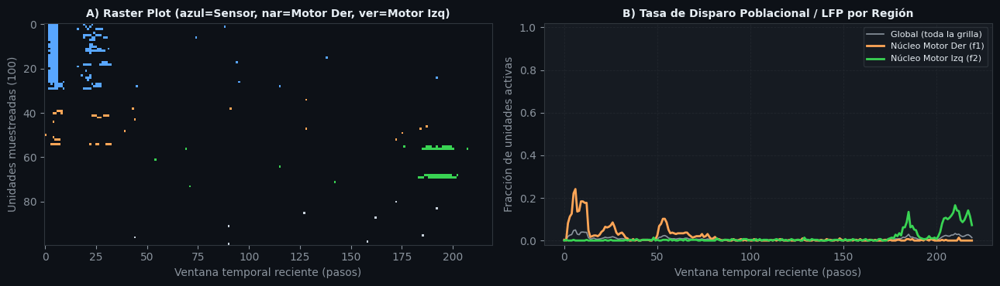

paso   320 | modo=conway_prob | arena=circular | carro (510, 432) dir 61°
choques obj=   0 | choques borde=   0 | distancia=390 (seguidos 0)
ruedas S1(der) f1=0.00 | S2(izq) f2=0.07  ->  u=0.47  w=-0.07  [ipsilateral/evita]
sensores [0 +30 +45 +90 -30 -45 -90] = 160 160 160 160 160 160 160 | activas=22/1600 (1.4%) | ATP medio=300


In [ ]:
# =====================================================================
# CELDA 3: DÍA 1 — Explorando la Caja de Arena y Reglas Probabilísticas
# =====================================================================
sim_dia1 = base.BootcampSim()
sim_dia1.brainMode = 'conway_prob'   # Prueba cambiar a 'conway_clasico' o 'bio_plastico'
sim_dia1.arenaShape = 'circular'     # 'cuadrada' o 'circular'

# Parámetros probabilísticos (Día 1 Mañana)
sim_dia1.pBirth = 0.90               # Probabilidad de activarse con 3 vecinos
sim_dia1.pSurvive = 0.95             # Probabilidad de sobrevivir con 2 o 3 vecinos
sim_dia1.pSpontaneous = 0.002        # Actividad neuronal espontánea
sim_dia1.refracSteps = 1             # Período refractario tras disparar
sim_dia1.reset()

# Correr 320 pasos (calculados en ~0.03 segundos) y mostrar reproductor HTML5
correr_y_visualizar_colab(sim_dia1, pasos_totales=320, grabar_cada=8, mostrar_video=True)

---
## Día 2 (Tarde): “Clausura sensorio-motriz y Plasticidad local”

En esta sección tu dupla (**Biología + Ingeniería**) debe programar sus propias restricciones biológicas locales editando el método `paso_automata_local` de la clase `MiPrototipoColab`.

### Criterios de diseño bioinspirado
1. **Metabolismo neuronal y Homeostasis (ATP):** Cada unidad posee una reserva energética (`self.energia`). Activarse consume ATP (`atpDecay`) y estar en reposo lo recupera (`atpRecovery`). Si la energía cae, disminuye la probabilidad de disparo (emulando depresión sináptica transitoria por hiperactividad y evitando que la grilla colapse o se sature).
2. **Plasticidad local dependiente de la historia:** Las unidades modifican dinámicamente su umbral de activación (`self.umbralLocal`) según su actividad histórica reciente. Por ejemplo, si una célula y sus vecinas se activan juntas con frecuencia, reducen el umbral requerido para activarse mutuamente (**traducción espacial de la plasticidad Hebbiana**), trazando rutas emergentes entre los sensores y los motores.

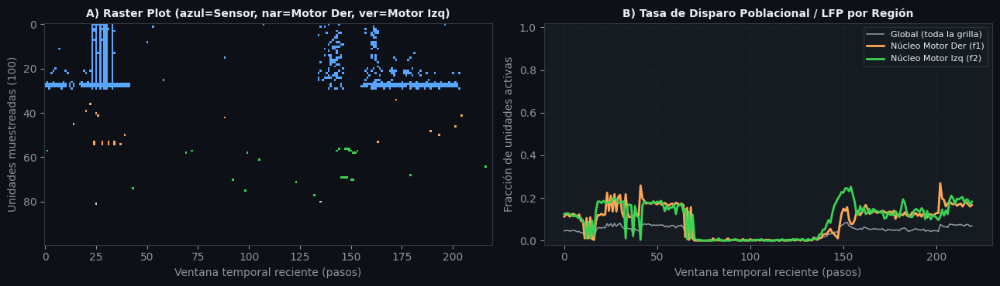

paso   320 | modo=conway_prob | arena=circular | carro (140, 520) dir 259°
choques obj=   0 | choques borde=   0 | distancia=502 (seguidos 0)
ruedas S1(der) f1=0.17 | S2(izq) f2=0.18  ->  u=0.75  w=-0.02  [ipsilateral/evita]
sensores [0 +30 +45 +90 -30 -45 -90] = 160 160 160  72 160 140 121 | activas=111/1600 (6.9%) | ATP medio=267


In [ ]:
# =====================================================================
# CELDA 4: ZONA DE DISEÑO DEL EQUIPO (Biología + Ingeniería)
# =====================================================================
class MiPrototipoColab(base.BootcampSim):
    """
    Hereda toda la física del vehículo y te permite programar únicamente
    las reglas locales del autómata y su plasticidad en NumPy.
    """
    def paso_automata_local(self, t, extStim):
        G = self.grid.reshape(base.N, base.N)
        ext2D = (extStim != 0).reshape(base.N, base.N)
        tipo2D = self.tipo.reshape(base.N, base.N)
        inhibMask = (tipo2D == 0)

        # 1. Contar vecinos excitatorios e inhibitorios (Vecindario de Moore)
        vecExc = self._contar_vecinos_moore((G == 1) & (~inhibMask))
        vecInh = self._contar_vecinos_moore(((G == 1) & inhibMask) | (ext2D & inhibMask))
        balance = vecExc - 1.2 * vecInh

        # 2. Restricción metabólica (ATP / Energía local)
        en2D = self.energia.reshape(base.N, base.N)
        factorATP = np.clip(en2D / base.E_MAX, 0.05, 1.0)
        R = self.rng.random_matrix((base.N, base.N))

        # 3. Activación modulada por umbral local plástico y período refractario
        disp = (self.refracGrid == 0) & (en2D > 20.0)
        superaUmbral = (balance >= self.umbralLocal - 0.5) & (balance <= self.umbralLocal + 1.5)
        nxt = (disp & superaUmbral & (R < self.pBirth * factorATP)) | (disp & (R < self.pSpontaneous))
        nxt = nxt | (ext2D & (~inhibMask))

        # 4. Actualizar ATP y Plasticidad Hebbiana espacial
        enNueva = np.where(nxt, en2D - self.atpDecay, en2D + self.atpRecovery)
        self.energia = np.clip(enNueva, 0.0, base.E_MAX).astype(np.float32).ravel()

        coactivadas = nxt & (vecExc >= 2)
        self.umbralLocal = np.where(
            coactivadas,
            np.maximum(1.6, self.umbralLocal - self.localHebbRate),
            self.umbralLocal + 0.002 * (3.0 - self.umbralLocal)
        ).astype(np.float32)

        seApaga = (G == 1) & (~nxt)
        self.refracGrid = np.maximum(0, self.refracGrid - 1)
        self.refracGrid[seApaga] = self.refracSteps

        self.grid = nxt.astype(np.uint8).ravel()


# Instanciar y probar el prototipo del equipo
mi_sim = MiPrototipoColab()
mi_sim.arenaShape = 'circular'
mi_sim.reset()
correr_y_visualizar_colab(mi_sim, pasos_totales=320, grabar_cada=4, mostrar_video=True)

---
## Día 3: “Emergencia, teleología y Ajuste del borde del caos”

¿Puede una cuadrícula restringida biológicamente que cambia dinámicamente realmente "calcular" o "aprender" a navegar sin un controlador central?

Esta celda ejecuta la **prueba oficial de desempeño de 40.000 pasos** en modo rápido (`run_headless`) y grafica la **Curva de Adaptación por Tramos** (tasa de choques por cada 1.000 pasos medida en bloques de 5.000 pasos).
* **El desafío del Borde del Caos:** Observarás que el autómata puede generar transitoriamente momentos en los que evade obstáculos de manera exitosa. El objetivo del ajuste fino de parámetros es **extender ese período de alto desempeño** evitando tanto la extinción de la actividad como la saturación caótica.

In [ ]:
# =====================================================================
# CELDA 5: DÍA 3 — Prueba de Desempeño de 40.000 pasos (Ranking Final)
# =====================================================================
sim_eval = MiPrototipoColab()
sim_eval.arenaShape = 'circular'
sim_eval.seedValue = 12345
sim_eval.reset()

# Corre 40.000 pasos en pocos segundos en CPU
base.run_headless(sim_eval, steps=40000, report_every=5000)

# Graficar la curva de adaptación por tramos (choques cada 1.000 pasos)
if sim_eval.tramos:
    pasos_t, tasas_t = zip(*sim_eval.tramos)
    plt.figure(figsize=(8, 3.5), facecolor='#0d1117')
    ax = plt.gca()
    ax.set_facecolor('#161b22')
    plt.plot([p / 1000 for p in pasos_t], tasas_t, marker='o', color='#58a6ff', lw=2)
    plt.title("Curva de Adaptación: Tasa de Choques por cada 1.000 pasos", color='#e6edf3')
    plt.xlabel("Paso de simulación (miles)", color='#8b949e')
    plt.ylabel("Choques / 1.000 pasos", color='#8b949e')
    plt.grid(color='#21262d', linestyle='--')
    ax.tick_params(colors='#8b949e')
    plt.tight_layout()
    plt.show()

---
##  Darwin Día 2 (Mañana): Selección Evolutiva de Condiciones y Restricciones Iniciales

> **Regla metodológica del Bootcamp:** No se permite utilizar algoritmos globales (como *backpropagation* o descenso de gradiente) para ajustar los pesos o estados de las celdas durante la navegación. No obstante, **sí se permite usar algoritmos globales que emulen un proceso evolutivo para seleccionar las condiciones iniciales y restricciones** que dan inicio al aprendizaje dinámico local.

La siguiente celda implementa un algoritmo evolutivo paralelo que evalúa poblaciones de candidatos (variando `pBirth`, `pSurvive`, `pSpontaneous`, `refracSteps`, `atpDecay`, `atpRecovery`, `localHebbRate` y `seedFrac`) y selecciona aquellos genotipos que maximizan la distancia explorada minimizando la tasa de colisiones.

In [ ]:
# =====================================================================
# CELDA 6: DÍA 2 (MAÑANA) — Selección Evolutiva de Condiciones Iniciales
# =====================================================================
# El aprendizaje ocurre estrictamente por propiedades locales durante la
# vida del vehículo, pero la "evolución" selecciona qué set de parámetros
# metabólicos y de plasticidad local sobrevive mejor en el entorno.

import concurrent.futures
import time
import numpy as np
import matplotlib.pyplot as plt
import bootcamp_conway_carro as base


def evaluar_individuo(args):
    """
    Evalúa un conjunto de restricciones biológicas locales durante N pasos.
    Retorna el fitness: distancia recorrida penalizada por la tasa de choques.
    """
    ind_id, genes, pasos_eval, arena, seed = args

    sim = base.BootcampSim()
    sim.brainMode = 'bio_plastico'
    sim.arenaShape = arena
    sim.seedValue = seed

    # Asignar genotipo (condiciones y restricciones iniciales)
    sim.pBirth = float(genes['pBirth'])
    sim.pSurvive = float(genes['pSurvive'])
    sim.pSpontaneous = float(genes['pSpontaneous'])
    sim.refracSteps = int(genes['refracSteps'])
    sim.atpDecay = float(genes['atpDecay'])
    sim.atpRecovery = float(genes['atpRecovery'])
    sim.localHebbRate = float(genes['localHebbRate'])
    sim.seedFrac = float(genes['seedFrac'])

    sim.reset()

    for _ in range(pasos_eval):
        sim.advance()

    choques_totales = sim.crashObj + sim.crashBorder
    tasa_choques_1k = (choques_totales / pasos_eval) * 1000.0

    # Función de Fitness: premiar exploración sin colapsar ni chocar
    # Penalizamos también si el cerebro se apaga por completo o se satura al 100%
    act_media = float(np.mean(sim.rateGlobalHist))
    penalizacion_coma = 500.0 if (act_media < 0.01 or act_media > 0.85) else 0.0

    fitness = (sim.distTraveled / 10.0) - (choques_totales * 18.0) - penalizacion_coma
    return ind_id, fitness, tasa_choques_1k, sim.distTraveled, act_media


def muestrear_genotipo_aleatorio(rng):
    """Genera un individuo aleatorio dentro de rangos biológicamente plausibles."""
    return {
        'pBirth': np.round(rng.uniform(0.55, 0.98), 3),
        'pSurvive': np.round(rng.uniform(0.50, 0.98), 3),
        'pSpontaneous': np.round(rng.uniform(0.0005, 0.012), 4),
        'refracSteps': int(rng.integers(0, 4)),
        'atpDecay': np.round(rng.uniform(10.0, 55.0), 1),
        'atpRecovery': np.round(rng.uniform(2.0, 15.0), 1),
        'localHebbRate': np.round(rng.uniform(0.005, 0.06), 3),
        'seedFrac': np.round(rng.uniform(0.15, 0.55), 2),
    }


def mutar_genotipo(padre, rng, fuerza=0.15):
    """Crea un descendiente con pequeñas variaciones sobre las restricciones del padre."""
    hijo = dict(padre)
    hijo['pBirth'] = float(np.clip(hijo['pBirth'] + rng.normal(0, 0.06 * fuerza), 0.3, 1.0))
    hijo['pSurvive'] = float(np.clip(hijo['pSurvive'] + rng.normal(0, 0.06 * fuerza), 0.3, 1.0))
    hijo['pSpontaneous'] = float(np.clip(hijo['pSpontaneous'] + rng.normal(0, 0.002 * fuerza), 0.0, 0.02))
    if rng.random() < 0.25:
        hijo['refracSteps'] = int(np.clip(hijo['refracSteps'] + int(rng.choice([-1, 1])), 0, 4))
    hijo['atpDecay'] = float(np.clip(hijo['atpDecay'] + rng.normal(0, 8.0 * fuerza), 5.0, 75.0))
    hijo['atpRecovery'] = float(np.clip(hijo['atpRecovery'] + rng.normal(0, 3.0 * fuerza), 1.0, 25.0))
    hijo['localHebbRate'] = float(np.clip(hijo['localHebbRate'] + rng.normal(0, 0.01 * fuerza), 0.001, 0.1))
    hijo['seedFrac'] = float(np.clip(hijo['seedFrac'] + rng.normal(0, 0.08 * fuerza), 0.05, 0.75))
    return hijo


def correr_evolucion(n_generaciones=6, tam_poblacion=12, pasos_eval=3000, arena='circular'):
    rng = np.random.default_rng(2027)
    poblacion = [muestrear_genotipo_aleatorio(rng) for _ in range(tam_poblacion)]

    hist_mejor_fit = []
    hist_mejor_choques = []
    mejor_global = None
    mejor_fit_global = -1e9

    print(f"Iniciando evolución: {n_generaciones} generaciones x {tam_poblacion} individuos ({pasos_eval} pasos c/u)")
    t0 = time.time()

    for gen in range(1, n_generaciones + 1):
        tareas = [(i, poblacion[i], pasos_eval, arena, 12345 + gen) for i in range(tam_poblacion)]

        # Evaluación paralela en los núcleos de CPU de Colab
        with concurrent.futures.ProcessPoolExecutor() as executor:
            resultados = list(executor.map(evaluar_individuo, tareas))

        # Ordenar de mayor a menor fitness
        resultados.sort(key=lambda x: x[1], reverse=True)
        top_id, top_fit, top_choques, top_dist, top_act = resultados[0]

        hist_mejor_fit.append(top_fit)
        hist_mejor_choques.append(top_choques)

        if top_fit > mejor_fit_global:
            mejor_fit_global = top_fit
            mejor_global = dict(poblacion[top_id])

        print(
            f"  Gen {gen:2d}/{n_generaciones} | Mejor Fitness={top_fit:7.1f} | "
            f"Choques/1k={top_choques:5.1f} | Dist={top_dist:7.0f} | Act.Media={top_act*100:4.1f}%"
        )

        # Selección elitista: los 4 mejores sobreviven y generan el resto por mutación
        elites = [ dict(poblacion[r[0]]) for r in resultados[:4] ]
        nueva_pob = list(elites)
        while len(nueva_pob) < tam_poblacion:
            padre = elites[int(rng.integers(0, len(elites)))]
            nueva_pob.append(mutar_genotipo(padre, rng, fuerza=1.0))
        poblacion = nueva_pob

    dt = time.time() - t0
    print(f"\nEvolución completada en {dt:.1f} s. Mejores condiciones iniciales encontradas:")
    for k, v in mejor_global.items():
        print(f"  - {k:14s}: {v:.4f}" if isinstance(v, float) else f"  - {k:14s}: {v}")

    # Graficar progreso evolutivo
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4), facecolor='#0d1117')
    for ax in (ax1, ax2):
        ax.set_facecolor('#161b22')
        ax.tick_params(colors='#8b949e')
        ax.grid(color='#21262d', linestyle='--')

    gens = np.arange(1, n_generaciones + 1)
    ax1.plot(gens, hist_mejor_fit, marker='o', color='#39d353', lw=2)
    ax1.set_title("Evolución del Fitness (Mayor es mejor)", color='#e6edf3', fontsize=10)
    ax1.set_xlabel("Generación", color='#8b949e')
    ax1.set_ylabel("Fitness", color='#8b949e')

    ax2.plot(gens, hist_mejor_choques, marker='s', color='#ffa657', lw=2)
    ax2.set_title("Tasa de Choques del Mejor Individuo (Menor es mejor)", color='#e6edf3', fontsize=10)
    ax2.set_xlabel("Generación", color='#8b949e')
    ax2.set_ylabel("Choques / 1.000 pasos", color='#8b949e')

    plt.tight_layout()
    plt.show()
    return mejor_global


# Ejecutar búsqueda evolutiva rápida y visualizar al campeón
mejores_condiciones = correr_evolucion(n_generaciones=5, tam_poblacion=10, pasos_eval=2500, arena='circular')